# [Lab 5-3] GAN (Generative Adversarial Network) 기반 MNIST 손글씨 숫자 생성 실습
---
이 노트북에서는 Generative Adversarial Network (GAN)를 구현하여 MNIST 손글씨 숫자를 생성합니다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers


gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)   # VRAM 전체 선점 방지
tf.config.optimizer.set_experimental_options({"remapper": False})  # 앞서 본 remapper 로그 제거

print("GPU:", gpus)

I0000 00:00:1790677873.028313 1969406 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790677873.069680 1969406 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790677874.331263 1969406 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


W0000 00:00:1790677874.799166 1969406 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


In [2]:
import os, sys
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "0"
os.environ["TF_CPP_VMODULE"] = "dso_loader=1,cuda_dso_loader=1"

print("exe:", sys.executable)
print("CUDA_VISIBLE_DEVICES:", repr(os.environ.get("CUDA_VISIBLE_DEVICES")))
print("LD_LIBRARY_PATH:", os.environ.get("LD_LIBRARY_PATH"))
print("torch 선로드:", "torch" in sys.modules)

import tensorflow as tf
print("GPU:", tf.config.list_physical_devices("GPU"))

exe: /home/chohi/PythonProjectLLM/.venv/bin/python
CUDA_VISIBLE_DEVICES: None
LD_LIBRARY_PATH: /usr/local/cuda-12.9/lib64
torch 선로드: False
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
with tf.device("/GPU:0"):
    x = tf.random.normal((4096, 4096))
    print(tf.matmul(x, x).device)   # .../device:GPU:0 이면 성공

/job:localhost/replica:0/task:0/device:GPU:0


W0000 00:00:1790677886.331745 1969406 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1790677886.436736 1969406 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 12674 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070 Ti, pci bus id: 0000:01:00.0, compute capability: 12.0a


## 1. 데이터 준비

In [4]:
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255.
x_train = np.expand_dims(x_train, -1)

BUFFER_SIZE = 60000
BATCH_SIZE = 256

train_dataset = tf.data.Dataset.from_tensor_slices(x_train).shuffle(BUFFER_SIZE).batch(BATCH_SIZE)

## 2. Generator 정의

In [5]:
def make_generator_model():
    model = tf.keras.Sequential()
    model.add(layers.Dense(7*7*256, use_bias=False, input_shape=(100,)))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Reshape((7, 7, 256)))
    model.add(layers.Conv2DTranspose(128, (5,5), strides=(1,1), padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Conv2DTranspose(64, (5,5), strides=(2,2), padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Conv2DTranspose(1, (5,5), strides=(2,2), padding="same", use_bias=False, activation="tanh"))
    return model

generator = make_generator_model()
generator.summary()

/home/chohi/PythonProjectLLM/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1790677893.601588 1970331 ptx_compiler_helpers.cc:154] *** WARNING *** Invoking ptxas with version 12.2.140, which corresponds to a CUDA version <=12.6.2. CUDA versions 12.x.y up to and including 12.6.2 miscompile certain edge cases around clamping.
Please upgrade to CUDA 12.6.3 or newer.
W0000 00:00:1790677893.607649 1970331 subprocess_compilation.cc:241] Falling back to the CUDA driver for PTX compilation; ptxas does not support CC 12.0
W0000 00:00:1790677893.607680 1970331 subprocess_compilation.cc:244] Used ptxas at /usr/bin/ptxas
W0000 00:00:1790677893.607739 1970331 gpu_kernel_to_blob_pass.cc:190] Failed to compile gen

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,944 (8.89 MB)

 Trainable params: 2,305,472 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

## 3. Discriminator 정의

In [6]:
def make_discriminator_model():
    model = tf.keras.Sequential()
    model.add(layers.Conv2D(64, (5,5), strides=(2,2), padding="same", input_shape=[28,28,1]))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128, (5,5), strides=(2,2), padding="same"))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(1))
    return model

discriminator = make_discriminator_model()
discriminator.summary()

/home/chohi/PythonProjectLLM/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

## 4. 손실 함수와 Optimizer

In [7]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

## 5. 학습 루프 정의

In [8]:
EPOCHS = 30
noise_dim = 100
num_examples_to_generate = 16

seed = tf.random.normal([num_examples_to_generate, noise_dim])

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, noise_dim])
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss

def train(dataset, epochs):
    for epoch in range(epochs):
        for image_batch in dataset:
            g_loss, d_loss = train_step(image_batch)
        print(f"Epoch {epoch+1}, Gen Loss: {g_loss:.4f}, Disc Loss: {d_loss:.4f}")

        generate_and_save_images(generator, epoch+1, seed)

def generate_and_save_images(model, epoch, test_input):
    predictions = model(test_input, training=False)
    fig = plt.figure(figsize=(4,4))

    for i in range(predictions.shape[0]):
        plt.subplot(4,4,i+1)
        plt.imshow(predictions[i,:,:,0]*127.5+127.5, cmap="gray")
        plt.axis("off")
    plt.suptitle(f"Epoch {epoch}")
    plt.show()

## 6. 모델 학습 실행

E0000 00:00:1790677911.157479 1969406 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape insequential_1_2/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1790677911.320011 1970146 cuda_dnn.cc:461] Loaded cuDNN version 91900
W0000 00:00:1790677911.404649 1971115 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1790677911.406113 1971120 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1790677911.407706 1971119 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1790677911.409938 1971118 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1790677911.412237 1971112 gpu_kernel_to_

Epoch 1, Gen Loss: 2.0532, Disc Loss: 0.6443


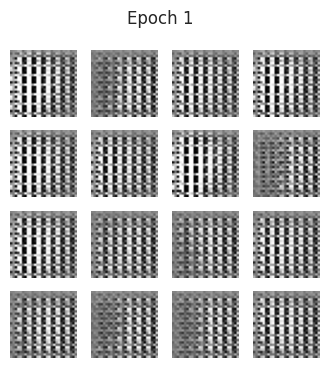

Epoch 2, Gen Loss: 1.0231, Disc Loss: 0.8963


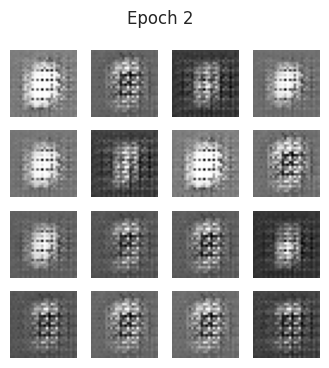

Epoch 3, Gen Loss: 1.0663, Disc Loss: 0.9745


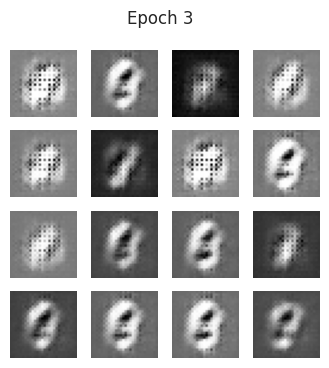

Epoch 4, Gen Loss: 1.4003, Disc Loss: 0.6961


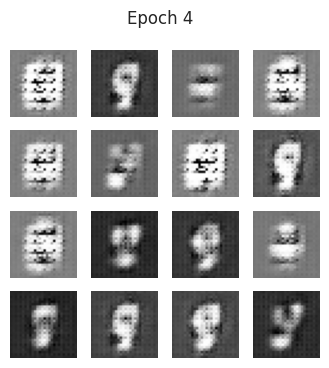

Epoch 5, Gen Loss: 1.4803, Disc Loss: 0.7345


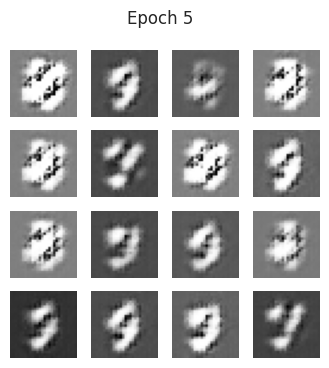

Epoch 6, Gen Loss: 1.2969, Disc Loss: 0.7614


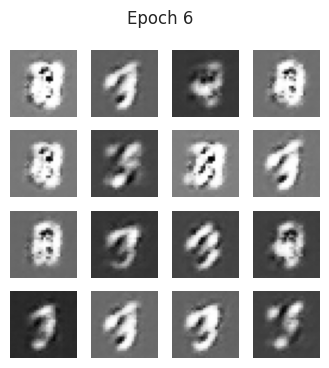

Epoch 7, Gen Loss: 1.3887, Disc Loss: 0.7557


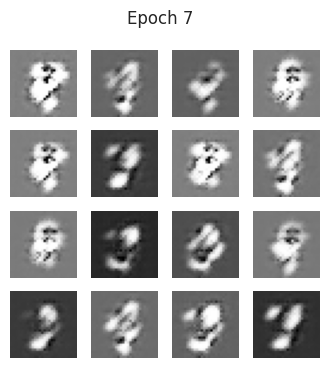

Epoch 8, Gen Loss: 1.9259, Disc Loss: 0.5266


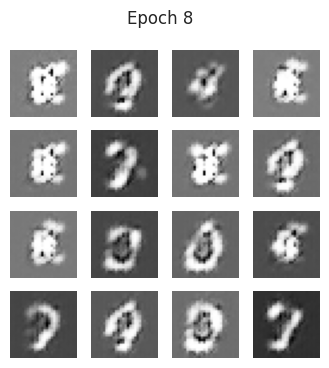

Epoch 9, Gen Loss: 1.8023, Disc Loss: 0.6175


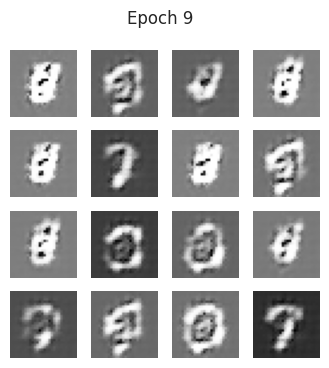

Epoch 10, Gen Loss: 2.1100, Disc Loss: 0.4713


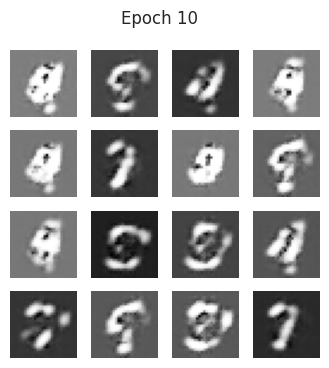

Epoch 11, Gen Loss: 1.8478, Disc Loss: 0.5731


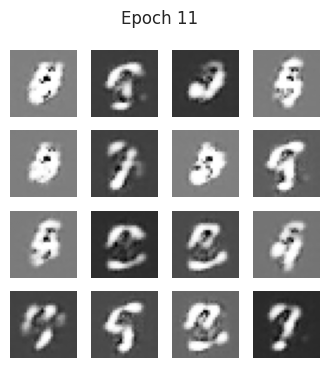

Epoch 12, Gen Loss: 2.3848, Disc Loss: 0.4544


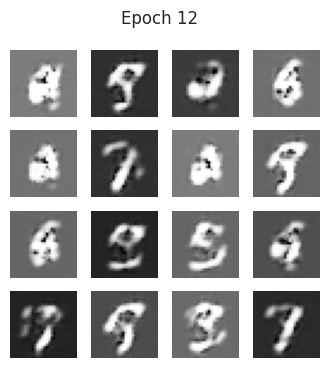

Epoch 13, Gen Loss: 2.0742, Disc Loss: 0.5414


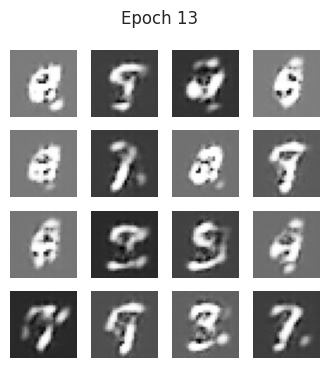

Epoch 14, Gen Loss: 2.0149, Disc Loss: 0.5084


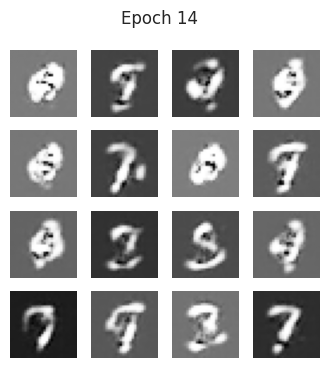

Epoch 15, Gen Loss: 2.4079, Disc Loss: 0.4451


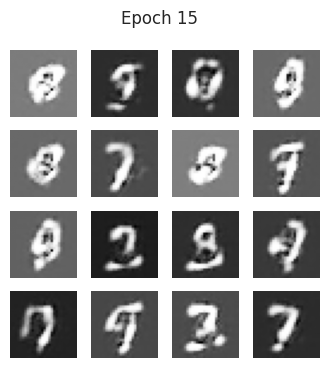

Epoch 16, Gen Loss: 2.1989, Disc Loss: 0.4510


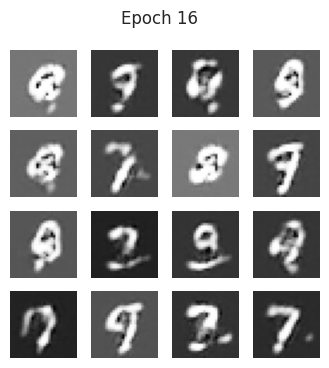

Epoch 17, Gen Loss: 2.1451, Disc Loss: 0.6163


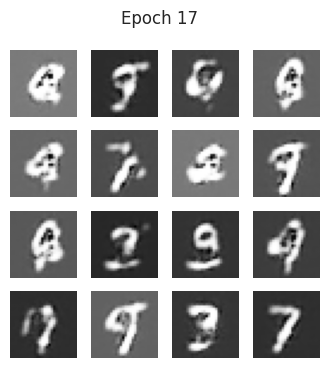

Epoch 18, Gen Loss: 2.2269, Disc Loss: 0.4345


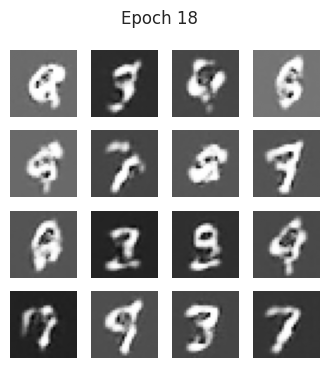

Epoch 19, Gen Loss: 2.5575, Disc Loss: 0.4574


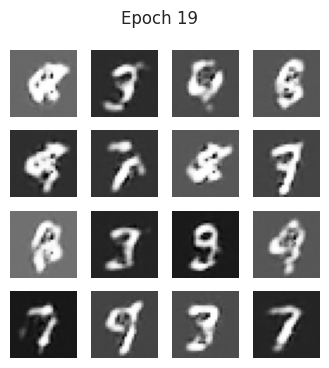

Epoch 20, Gen Loss: 2.3031, Disc Loss: 0.4898


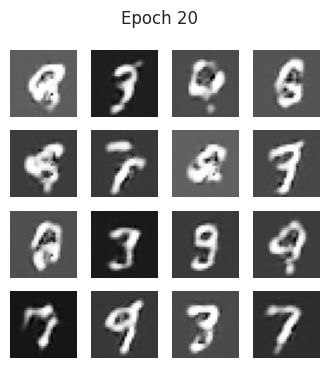

Epoch 21, Gen Loss: 2.6795, Disc Loss: 0.4437


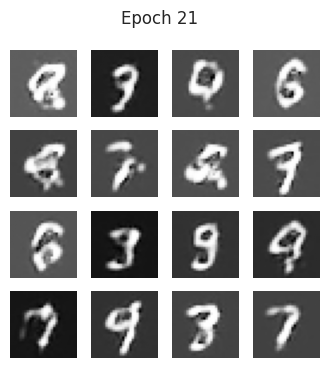

Epoch 22, Gen Loss: 2.3654, Disc Loss: 0.4805


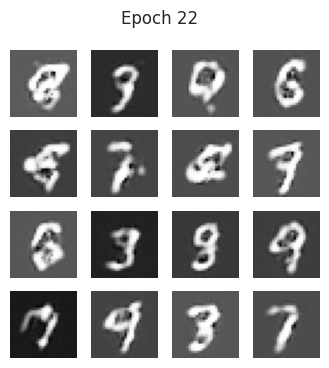

Epoch 23, Gen Loss: 2.3758, Disc Loss: 0.5657


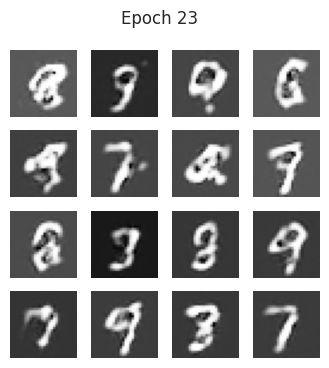

Epoch 24, Gen Loss: 2.3667, Disc Loss: 0.4209


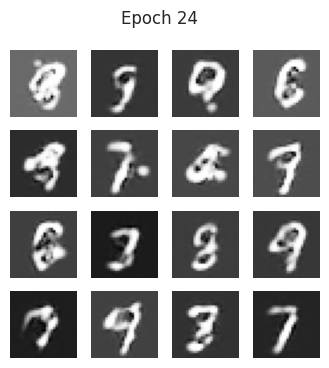

Epoch 25, Gen Loss: 2.4250, Disc Loss: 0.4838


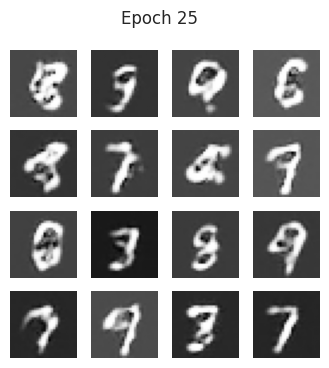

Epoch 26, Gen Loss: 2.4576, Disc Loss: 0.5117


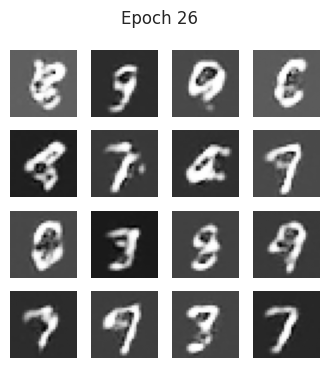

Epoch 27, Gen Loss: 2.0676, Disc Loss: 0.4890


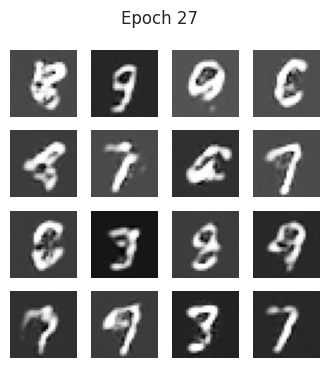

Epoch 28, Gen Loss: 2.2971, Disc Loss: 0.4289


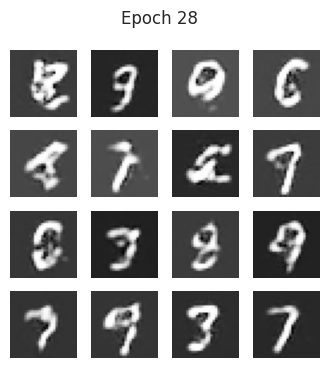

Epoch 29, Gen Loss: 2.3832, Disc Loss: 0.5526


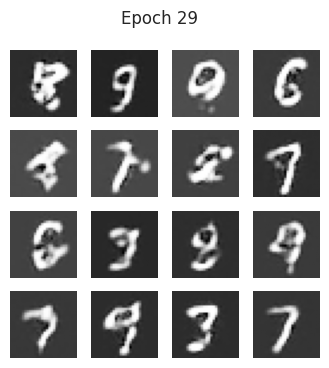

Epoch 30, Gen Loss: 1.9980, Disc Loss: 0.4884


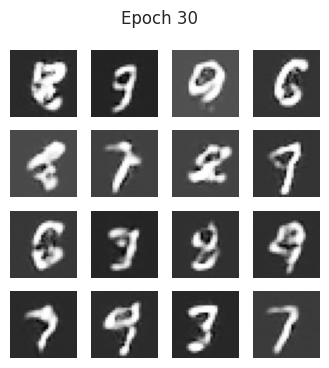

In [9]:
train(train_dataset, EPOCHS)

## 7. 최종 손글씨 생성

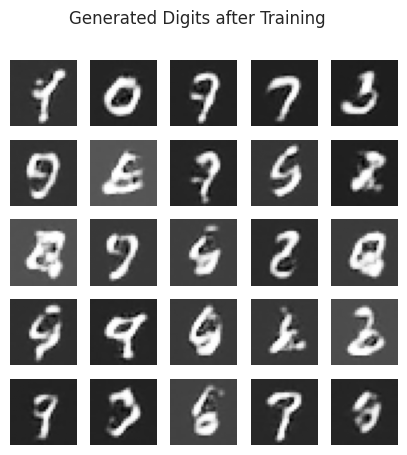

In [10]:
noise = tf.random.normal([25, noise_dim])
generated_images = generator(noise, training=False)

plt.figure(figsize=(5,5))
for i in range(generated_images.shape[0]):
    plt.subplot(5,5,i+1)
    plt.imshow(generated_images[i,:,:,0]*127.5+127.5, cmap="gray")
    plt.axis("off")
plt.suptitle("Generated Digits after Training")
plt.show()